In [ ]:
!pip install yfinance


In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date

In [ ]:
df = yf.Ticker("SILVERBEES.NS").history(start="2021-01-01" , end = date.today())
df = df[['Open' , 'High' , 'Low' , 'Close' , 'Volume']]
# print(df.head())
print(df)

                                 Open        High         Low       Close  \
Date                                                                        
2022-02-04 00:00:00+05:30   60.959599   60.959599   60.959599   60.959599   
2022-02-07 00:00:00+05:30   60.000000   64.339996   59.439999   61.770000   
2022-02-08 00:00:00+05:30   62.000000   63.000000   61.549999   62.279999   
2022-02-09 00:00:00+05:30   62.500000   63.000000   62.009998   62.770000   
2022-02-10 00:00:00+05:30   63.000000   64.900002   62.200001   62.799999   
...                               ...         ...         ...         ...   
2026-11-11 00:00:00+05:30  175.869995  177.199997  174.750000  176.839996   
2026-11-12 00:00:00+05:30  172.600006  173.360001  170.600006  171.369995   
2026-11-13 00:00:00+05:30  170.000000  170.149994  167.660004  168.759995   
2026-11-16 00:00:00+05:30  162.339996  162.979996  160.250000  160.610001   
2026-11-17 00:00:00+05:30         NaN         NaN         NaN         NaN   

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1180 entries, 2022-02-04 00:00:00+05:30 to 2026-11-17 00:00:00+05:30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1179 non-null   float64
 1   High    1179 non-null   float64
 2   Low     1179 non-null   float64
 3   Close   1179 non-null   float64
 4   Volume  1180 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 55.3 KB
None


In [ ]:
print(df.describe())

              Open         High          Low        Close        Volume
count  1179.000000  1179.000000  1179.000000  1179.000000  1.180000e+03
mean    109.228922   110.179728   107.971365   109.064351  1.608019e+07
std      61.727952    62.807162    60.546128    61.698613  3.372758e+07
min      52.599998    53.000000    46.150002    52.270000  0.000000e+00
25%      68.770000    69.189999    68.430000    68.855000  1.413554e+06
50%      82.989998    83.410004    82.489998    83.010002  4.958759e+06
75%     118.614998   119.320000   117.954998   118.985001  1.587064e+07
max     351.200012   360.000000   346.149994   351.910004  3.916029e+08


In [ ]:
#q2
df_t = yf.Ticker("SILVERBEES.NS").history(start="2026-11-09" , end = date.today() , interval = "1m")
df_t

ERROR:yfinance:$SILVERBEES.NS: possibly delisted; no price data found  (1m 2026-11-09 -> 2026-11-18) (Yahoo error = "1m data not available for startTime=1794162600 and endTime=1794940200. Only 8 days worth of 1m granularity data are allowed to be fetched per request.")


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,


In [ ]:
#q3
tickers = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ITC.NS"]

# Use yf.download for multiple tickers
df_t = yf.download(tickers, start="2025-11-09", end=date.today())
df_t = df_t['Close']
df_t

/tmp/ipykernel_611/1300447740.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(tickers, start="2025-11-09", end=date.today())
[*********************100%***********************]  5 of 5 completed


Ticker,HDFCBANK.NS,INFY.NS,ITC.NS,RELIANCE.NS,TCS.NS
Date,,,,,
2025-11-10,968.481873,1448.266357,386.690369,1482.445801,2900.037354
2025-11-11,975.564697,1464.342285,387.929932,1486.526978,2920.935547
2025-11-12,973.400513,1484.819824,388.072937,1504.543579,3002.227051
2025-11-13,970.596924,1475.346558,386.833405,1503.946411,2977.206787
2025-11-14,973.498840,1438.027588,389.169464,1511.909546,2977.494629
...,...,...,...,...,...
2026-11-11,806.599976,1155.000000,285.000000,1335.400024,2472.100098
2026-11-12,812.299988,1151.199951,284.049988,1339.699951,2442.399902
2026-11-13,804.000000,1141.500000,285.000000,1339.699951,2407.500000


In [ ]:
#q4
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

def get_data(ticker , start , end , interval) :
  df = yf.download(ticker, start, end, interval, progress=False)

  if df.empty:
      print(f"Unable to fetch data for '{ticker}' (invalid ticker or no data found)")
      return None
  else:
      print(f"\nSuccessfully retrieved data for '{ticker}'")
      return df

tck = "SILVERBEES.NS"
get_data(tck , "2025-01-01" , date.today() , "1d")
tck = "HIV.NS"
get_data(tck , "2026-01-01" , date.today() , "1d")


Successfully retrieved data for 'SILVERBEES.NS'


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: HIV.NS"}}}
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HIV.NS']: YFTzMissingError('possibly delisted; no timezone found')


Unable to fetch data for 'HIV.NS' (invalid ticker or no data found)


In [ ]:
#q5
import time
readings = []

for i in range(0,5) :
  df = yf.download("SILVERBEES.NS" , period = "1d" , interval = "1m")
  readings.append( df['Close'].iloc[-1].item() )
  time.sleep(1)

# df = pd.to_frame(coulmns = ['Close price'])
df = pd.DataFrame(readings , columns = ['close price'])
df.to_csv("stock_prices.csv")


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
df = yf.download("SILVERBEES.NS" , start = '2025-01-01' , end = date.today() , multi_level_index=False)
# df.isna().sum()
# df = df.reset_index()
# df['Date'] = pd.to_datetime(df['Date'])
# print(df['Date'].dtype)
# x = df[df['Date'].diff().dt.days.fillna(1) != 1].shape[0]
# print("No.of non-trading days :" , x)
if df.index.tz is None :
  df.index = df.index.tz_localize('Asia/Kolkata')
df.index.tz

df["diff"] = df['Close'].diff().abs()
df.sort_values(["diff"] , ascending = False).head(10)

# using IQR method

# Q1 = df['Volume'].quantile(0.25)
# Q3 = df['Volume'].quantile(0.75)
# IQR = Q3 - Q1

# lower_bound = Q1 - 1.5*IQR
# upper_bound = Q3 + 1.5*IQR

# df[(df['Volume'] < lower_bound) | (df['Volume'] > upper_bound)].shape[0]


# using Z-score
# mean = df['Volume'].mean()
# std = df['Volume'].std()

# df['Zscore'] = (df['Volume'] - df['Volume'].mean()) / df['Volume'].std()

# df[['Open' , 'Volume']][df['Zscore'].abs() <= 3]

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume,diff
Date,,,,,,
2026-02-02 00:00:00+05:30,219.940002,252.490005,205.020004,252.490005,321774758,66.540009
2026-01-30 00:00:00+05:30,286.480011,337.799988,276.660004,329.000000,391602898,65.429993
2026-01-22 00:00:00+05:30,276.269989,302.980011,249.110001,299.600006,348178533,34.410004
2026-02-05 00:00:00+05:30,236.419998,241.800003,224.000000,234.899994,216470548,29.150009
2026-02-03 00:00:00+05:30,247.339996,258.799988,220.699997,224.699997,259120035,27.399994
2026-03-23 00:00:00+05:30,193.520004,214.889999,189.350006,211.779999,191512865,26.379990
2026-01-27 00:00:00+05:30,317.850006,321.480011,305.700012,310.399994,223275742,25.119995
2026-03-02 00:00:00+05:30,274.649994,276.000000,265.149994,265.149994,151660105,21.839996
2026-05-15 00:00:00+05:30,249.850006,262.600006,248.000000,262.600006,66470348,21.079987


<Axes: ylabel='Frequency'>

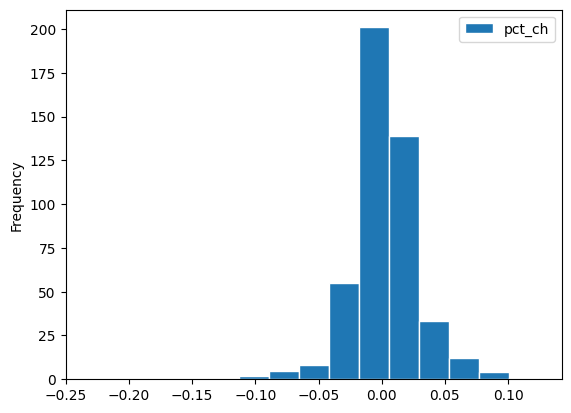

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

df['pct_ch'] = df['Close'].pct_change()
ret = df['Close']
df['log_ret'] = np.log( df['Close'] / df['Close'].shift(1) )
df.plot.hist(column = ['pct_ch'] , bins = 5)

In [ ]:
df['mf'] = np.maximum( df['Close']  , df['Close'].shift(1) )
df['Drawdown'] = (df['Close'] - df['mf']) / df['mf']

trough_date = df['Drawdown'].idxmin()
peak_date = df.loc[:trough_date , 'Close'].idxmax()
print(trough_date , peak_date)

2026-02-02 00:00:00+05:30 2026-01-29 00:00:00+05:30


In [ ]:
df['rt'] = (df['Close'] - df['Close'].shift(1)) / df['Close'].shift(1)
df['rt+1'] = (df['Close'].shift(-1) - df['Close']) / df['Close']

valid = df[['rt', 'rt+1']].dropna()

cov_xy = np.cov(valid['rt'], valid['rt+1'])[0, 1]

#correlation
# corr = cov_xy / (df['rt'].std() * df['rt+1'].std())
print(cov_xy)

NameError: name 'cov' is not defined